24/11/2026

# Exercise 1


Disk parameters:
a = 0.002, i = 75.0 deg, Rin = 6.0 Rg, Rout = 30.0 Rg, q = -2.5



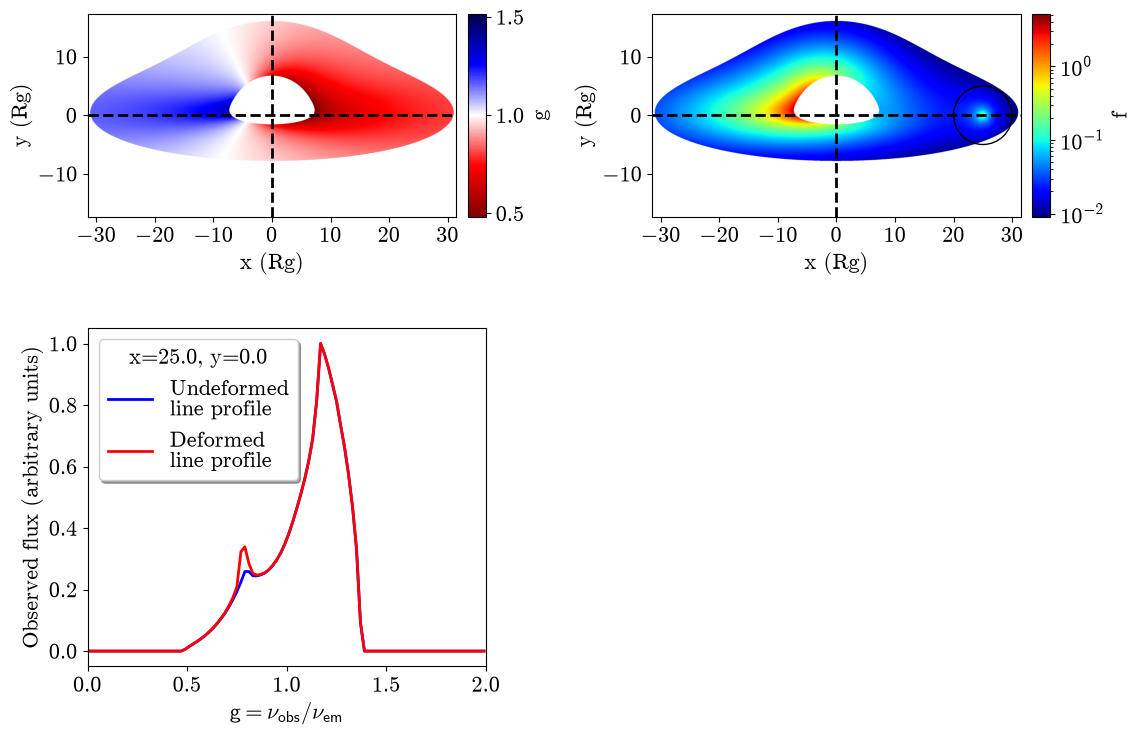

In [1]:
#
# Influence of a point-like microlens on the observed profile of the Fe Kalpha
# spectral line emitted from a relativistic accretion disk whose simulated image
# is stored in the specified input FITS file
#

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2,
    'figure.figsize': [11.69, 8.27]
})

# Distance from the point-like microlens
def u(x, y, xd, yd, re):
    return np.sqrt((x - xd)**2 + (y - yd)**2) / re

# Amplification of the point-like microlens
def amp(x, y, xd, yd, re):
    d = u(x, y, xd, yd, re)
    a = np.full(np.shape(d), np.inf)
    ind = np.where(d != 0)
    a[ind] = (d[ind]**2 + 2.0) / (d[ind] * np.sqrt(d[ind]**2 + 4.0))
    return a

# Input FITS file name (without extension)
filename = 'disk'
# Number of spectral line bins
nbin = 100
# Coordinates and projected Einstein radius (all in R_g) of the point-like microlens
xd = 25.0
yd = 0.0
re = 5.0

# Create the necessary I/O file names
fitsfile = filename + '.fits.gz'
linedat = f'line_x{xd}_y{yd}.dat'
pngfig = f'{filename}_x{xd}_y{yd}.png'

# Read the primary HDU header
h0 = fits.getheader(fitsfile, 0)
a = h0["SPIN"]
theta = h0["ANGLE"]
rin = h0["RINN"]
rout = h0["ROUT"]
q = h0["INDEX"]
print(f"\nDisk parameters:\na = {a}, i = {theta} deg, Rin = {rin} Rg, Rout = {rout} Rg, q = {q}\n")

# Read the data and header from the shift image
g, h1 = fits.getdata(fitsfile, 'SHIFT', header=True)
nx = h1["NAXIS1"]
ny = h1["NAXIS2"]
c1 = h1["CONTENT"]
xt = h1["CTYPE1"]
yt = h1["CTYPE2"]
xu = h1["CUNIT1"]
yu = h1["CUNIT2"]
i0 = h1["CRPIX1"]
j0 = h1["CRPIX2"]
x0 = h1["CRVAL1"]
y0 = h1["CRVAL2"]
dx = h1["CDELT1"]
dy = h1["CDELT2"]

# Extents of x and y axes
xext = (i0 - 1) * dx
yext = (j0 - 1) * dy

# Read the data and header from the flux image
f, h2 = fits.getdata(fitsfile, 'FLUX', header=True)
c2 = h2["CONTENT"]

# Undeformed line profile
valid = ~np.isnan(g) & ~np.isnan(f)
gg = g[valid]
ff = f[valid]

# Compute histogram (binning) directly using np.histogram
gbin = np.linspace(0.0, 2.0, nbin + 1)
fobs, _ = np.histogram(gg, bins=gbin, weights=ff)

# Normalize the maximum flux to 1
fmax = np.max(fobs)
fobs /= fmax

# Find the bin centers
gobs = (gbin[:-1] + gbin[1:]) / 2.0

# Amplified disk flux due to microlensing
x = np.linspace(-xext, xext, nx)
y = np.linspace(-yext, yext, ny)
xi, yi = np.meshgrid(x, y, sparse=False, indexing='xy')
f *= amp(xi, yi, xd, yd, re)

# Microlensed line profile normalized to its undeformed profile
ff_ml = f[valid]
fml, _ = np.histogram(gg, bins=gbin, weights=ff_ml)
fml /= fmax

# Save the spectral line profile
np.savetxt(linedat, np.transpose([gobs, fobs, fml]), fmt='%.7f %.7f %.7f')

# Plot the shift image of the disk
gext = max(1.0 - np.nanmin(g), np.nanmax(g) - 1.0)
ax1 = plt.subplot(221)
im1 = ax1.imshow(g, extent=[-xext, xext, yext, -yext], cmap='seismic_r', vmin=1.0 - gext, vmax=1.0 + gext)
ax1.locator_params(axis='x', nbins=7)
ax1.set_xlabel(f'{xt} ({xu})')
ax1.set_ylabel(f'{yt} ({yu})')
ax1.axhline(0, color='k', linestyle='--')
ax1.axvline(0, color='k', linestyle='--')
ax1.invert_yaxis()
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", "5%", pad="3%")
cbar1 = plt.colorbar(im1, cax=cax1)
cbar1.set_label(c1)

# Plot the flux image of the disk
ax2 = plt.subplot(222)
im2 = ax2.imshow(f, extent=[-xext, xext, yext, -yext], cmap='jet', norm=LogNorm(clip=True))
ax2.locator_params(axis='x', nbins=7)
# Projected Einstein ring of the microlens
ax2.add_patch(Circle((xd, yd), re, color='k', fill=False))
ax2.set_xlabel(f'{xt} ({xu})')
ax2.set_ylabel(f'{yt} ({yu})')
ax2.axhline(0, color='k', linestyle='--')
ax2.axvline(0, color='k', linestyle='--')
ax2.invert_yaxis()
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", "5%", pad="3%")
cbar2 = plt.colorbar(im2, cax=cax2)
cbar2.set_label(c2)

# Plot the undeformed and deformed line profiles
ax3 = plt.subplot(223)
ax3.plot(gobs, fobs, 'b-', label='Undeformed\nline profile')
ax3.plot(gobs, fml, 'r-', label='Deformed\nline profile')
ax3.set_xlim(0.0, 2.0)
ax3.set_xlabel(r'$\mathsf{g=\nu_{obs}/\nu_{em}}$')
ax3.set_ylabel('Observed flux (arbitrary units)')
ax3.legend(loc='upper left', title=f'x={xd}, y={yd}', fancybox=True, shadow=True)

# Adjust subplot spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout()
plt.savefig(pngfig, dpi=300, bbox_inches='tight')
plt.show()



Disk parameters:
a = 0.002, i = 75.0 deg, Rin = 6.0 Rg, Rout = 30.0 Rg, q = -2.5



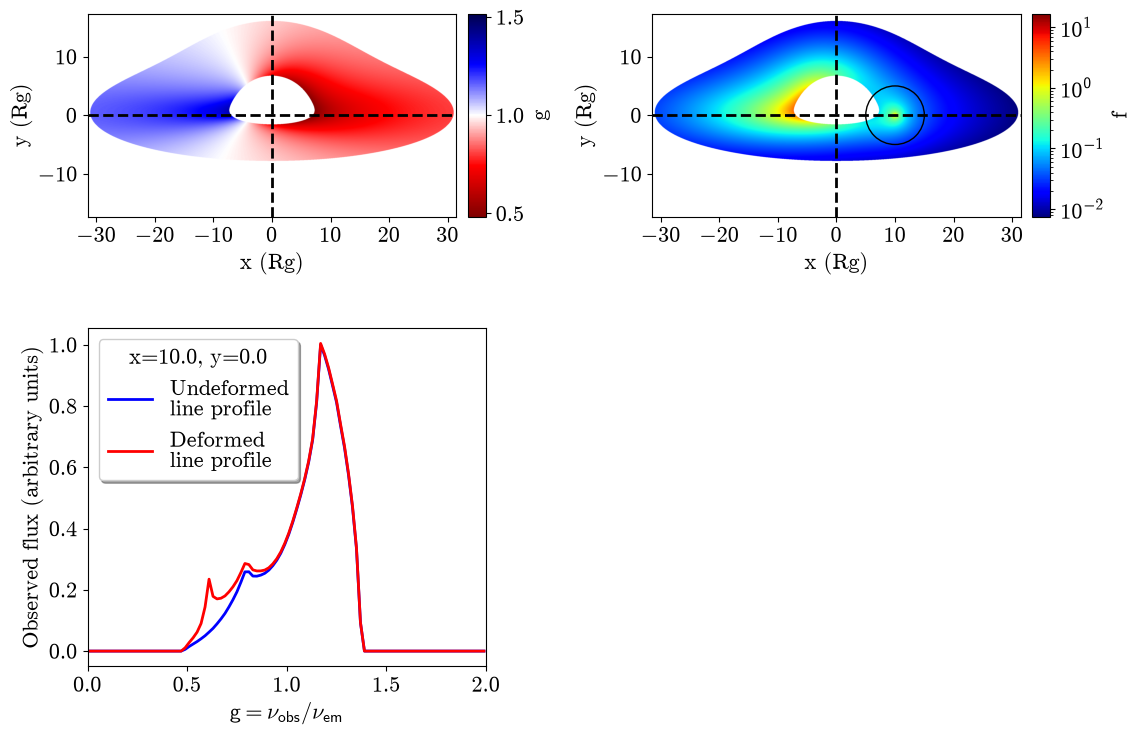

In [2]:
#
# Influence of a point-like microlens on the observed profile of the Fe Kalpha
# spectral line emitted from a relativistic accretion disk whose simulated image
# is stored in the specified input FITS file
#

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2,
    'figure.figsize': [11.69, 8.27]
})

# Distance from the point-like microlens
def u(x, y, xd, yd, re):
    return np.sqrt((x - xd)**2 + (y - yd)**2) / re

# Amplification of the point-like microlens
def amp(x, y, xd, yd, re):
    d = u(x, y, xd, yd, re)
    a = np.full(np.shape(d), np.inf)
    ind = np.where(d != 0)
    a[ind] = (d[ind]**2 + 2.0) / (d[ind] * np.sqrt(d[ind]**2 + 4.0))
    return a

# Input FITS file name (without extension)
filename = 'disk'
# Number of spectral line bins
nbin = 100
# Coordinates and projected Einstein radius (all in R_g) of the point-like microlens
xd = 10.0
yd = 0.0
re = 5.0

# Create the necessary I/O file names
fitsfile = filename + '.fits.gz'
linedat = f'line_x{xd}_y{yd}.dat'
pngfig = f'{filename}_x{xd}_y{yd}.png'

# Read the primary HDU header
h0 = fits.getheader(fitsfile, 0)
a = h0["SPIN"]
theta = h0["ANGLE"]
rin = h0["RINN"]
rout = h0["ROUT"]
q = h0["INDEX"]
print(f"\nDisk parameters:\na = {a}, i = {theta} deg, Rin = {rin} Rg, Rout = {rout} Rg, q = {q}\n")

# Read the data and header from the shift image
g, h1 = fits.getdata(fitsfile, 'SHIFT', header=True)
nx = h1["NAXIS1"]
ny = h1["NAXIS2"]
c1 = h1["CONTENT"]
xt = h1["CTYPE1"]
yt = h1["CTYPE2"]
xu = h1["CUNIT1"]
yu = h1["CUNIT2"]
i0 = h1["CRPIX1"]
j0 = h1["CRPIX2"]
x0 = h1["CRVAL1"]
y0 = h1["CRVAL2"]
dx = h1["CDELT1"]
dy = h1["CDELT2"]

# Extents of x and y axes
xext = (i0 - 1) * dx
yext = (j0 - 1) * dy

# Read the data and header from the flux image
f, h2 = fits.getdata(fitsfile, 'FLUX', header=True)
c2 = h2["CONTENT"]

# Undeformed line profile
valid = ~np.isnan(g) & ~np.isnan(f)
gg = g[valid]
ff = f[valid]

# Compute histogram (binning) directly using np.histogram
gbin = np.linspace(0.0, 2.0, nbin + 1)
fobs, _ = np.histogram(gg, bins=gbin, weights=ff)

# Normalize the maximum flux to 1
fmax = np.max(fobs)
fobs /= fmax

# Find the bin centers
gobs = (gbin[:-1] + gbin[1:]) / 2.0

# Amplified disk flux due to microlensing
x = np.linspace(-xext, xext, nx)
y = np.linspace(-yext, yext, ny)
xi, yi = np.meshgrid(x, y, sparse=False, indexing='xy')
f *= amp(xi, yi, xd, yd, re)

# Microlensed line profile normalized to its undeformed profile
ff_ml = f[valid]
fml, _ = np.histogram(gg, bins=gbin, weights=ff_ml)
fml /= fmax

# Save the spectral line profile
np.savetxt(linedat, np.transpose([gobs, fobs, fml]), fmt='%.7f %.7f %.7f')

# Plot the shift image of the disk
gext = max(1.0 - np.nanmin(g), np.nanmax(g) - 1.0)
ax1 = plt.subplot(221)
im1 = ax1.imshow(g, extent=[-xext, xext, yext, -yext], cmap='seismic_r', vmin=1.0 - gext, vmax=1.0 + gext)
ax1.locator_params(axis='x', nbins=7)
ax1.set_xlabel(f'{xt} ({xu})')
ax1.set_ylabel(f'{yt} ({yu})')
ax1.axhline(0, color='k', linestyle='--')
ax1.axvline(0, color='k', linestyle='--')
ax1.invert_yaxis()
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", "5%", pad="3%")
cbar1 = plt.colorbar(im1, cax=cax1)
cbar1.set_label(c1)

# Plot the flux image of the disk
ax2 = plt.subplot(222)
im2 = ax2.imshow(f, extent=[-xext, xext, yext, -yext], cmap='jet', norm=LogNorm(clip=True))
ax2.locator_params(axis='x', nbins=7)
# Projected Einstein ring of the microlens
ax2.add_patch(Circle((xd, yd), re, color='k', fill=False))
ax2.set_xlabel(f'{xt} ({xu})')
ax2.set_ylabel(f'{yt} ({yu})')
ax2.axhline(0, color='k', linestyle='--')
ax2.axvline(0, color='k', linestyle='--')
ax2.invert_yaxis()
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", "5%", pad="3%")
cbar2 = plt.colorbar(im2, cax=cax2)
cbar2.set_label(c2)

# Plot the undeformed and deformed line profiles
ax3 = plt.subplot(223)
ax3.plot(gobs, fobs, 'b-', label='Undeformed\nline profile')
ax3.plot(gobs, fml, 'r-', label='Deformed\nline profile')
ax3.set_xlim(0.0, 2.0)
ax3.set_xlabel(r'$\mathsf{g=\nu_{obs}/\nu_{em}}$')
ax3.set_ylabel('Observed flux (arbitrary units)')
ax3.legend(loc='upper left', title=f'x={xd}, y={yd}', fancybox=True, shadow=True)

# Adjust subplot spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout()
plt.savefig(pngfig, dpi=300, bbox_inches='tight')
plt.show()



Disk parameters:
a = 0.002, i = 75.0 deg, Rin = 6.0 Rg, Rout = 30.0 Rg, q = -2.5



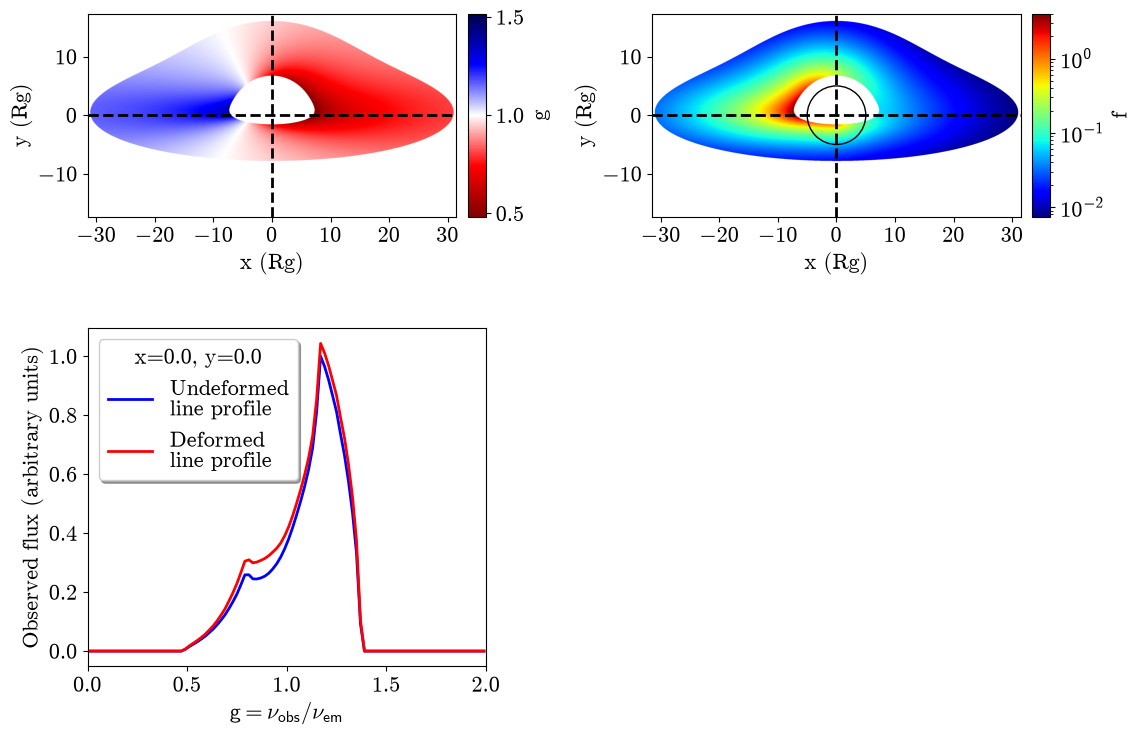

In [3]:
#
# Influence of a point-like microlens on the observed profile of the Fe Kalpha
# spectral line emitted from a relativistic accretion disk whose simulated image
# is stored in the specified input FITS file
#

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2,
    'figure.figsize': [11.69, 8.27]
})

# Distance from the point-like microlens
def u(x, y, xd, yd, re):
    return np.sqrt((x - xd)**2 + (y - yd)**2) / re

# Amplification of the point-like microlens
def amp(x, y, xd, yd, re):
    d = u(x, y, xd, yd, re)
    a = np.full(np.shape(d), np.inf)
    ind = np.where(d != 0)
    a[ind] = (d[ind]**2 + 2.0) / (d[ind] * np.sqrt(d[ind]**2 + 4.0))
    return a

# Input FITS file name (without extension)
filename = 'disk'
# Number of spectral line bins
nbin = 100
# Coordinates and projected Einstein radius (all in R_g) of the point-like microlens
xd = 0.0
yd = 0.0
re = 5.0

# Create the necessary I/O file names
fitsfile = filename + '.fits.gz'
linedat = f'line_x{xd}_y{yd}.dat'
pngfig = f'{filename}_x{xd}_y{yd}.png'

# Read the primary HDU header
h0 = fits.getheader(fitsfile, 0)
a = h0["SPIN"]
theta = h0["ANGLE"]
rin = h0["RINN"]
rout = h0["ROUT"]
q = h0["INDEX"]
print(f"\nDisk parameters:\na = {a}, i = {theta} deg, Rin = {rin} Rg, Rout = {rout} Rg, q = {q}\n")

# Read the data and header from the shift image
g, h1 = fits.getdata(fitsfile, 'SHIFT', header=True)
nx = h1["NAXIS1"]
ny = h1["NAXIS2"]
c1 = h1["CONTENT"]
xt = h1["CTYPE1"]
yt = h1["CTYPE2"]
xu = h1["CUNIT1"]
yu = h1["CUNIT2"]
i0 = h1["CRPIX1"]
j0 = h1["CRPIX2"]
x0 = h1["CRVAL1"]
y0 = h1["CRVAL2"]
dx = h1["CDELT1"]
dy = h1["CDELT2"]

# Extents of x and y axes
xext = (i0 - 1) * dx
yext = (j0 - 1) * dy

# Read the data and header from the flux image
f, h2 = fits.getdata(fitsfile, 'FLUX', header=True)
c2 = h2["CONTENT"]

# Undeformed line profile
valid = ~np.isnan(g) & ~np.isnan(f)
gg = g[valid]
ff = f[valid]

# Compute histogram (binning) directly using np.histogram
gbin = np.linspace(0.0, 2.0, nbin + 1)
fobs, _ = np.histogram(gg, bins=gbin, weights=ff)

# Normalize the maximum flux to 1
fmax = np.max(fobs)
fobs /= fmax

# Find the bin centers
gobs = (gbin[:-1] + gbin[1:]) / 2.0

# Amplified disk flux due to microlensing
x = np.linspace(-xext, xext, nx)
y = np.linspace(-yext, yext, ny)
xi, yi = np.meshgrid(x, y, sparse=False, indexing='xy')
f *= amp(xi, yi, xd, yd, re)

# Microlensed line profile normalized to its undeformed profile
ff_ml = f[valid]
fml, _ = np.histogram(gg, bins=gbin, weights=ff_ml)
fml /= fmax

# Save the spectral line profile
np.savetxt(linedat, np.transpose([gobs, fobs, fml]), fmt='%.7f %.7f %.7f')

# Plot the shift image of the disk
gext = max(1.0 - np.nanmin(g), np.nanmax(g) - 1.0)
ax1 = plt.subplot(221)
im1 = ax1.imshow(g, extent=[-xext, xext, yext, -yext], cmap='seismic_r', vmin=1.0 - gext, vmax=1.0 + gext)
ax1.locator_params(axis='x', nbins=7)
ax1.set_xlabel(f'{xt} ({xu})')
ax1.set_ylabel(f'{yt} ({yu})')
ax1.axhline(0, color='k', linestyle='--')
ax1.axvline(0, color='k', linestyle='--')
ax1.invert_yaxis()
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", "5%", pad="3%")
cbar1 = plt.colorbar(im1, cax=cax1)
cbar1.set_label(c1)

# Plot the flux image of the disk
ax2 = plt.subplot(222)
im2 = ax2.imshow(f, extent=[-xext, xext, yext, -yext], cmap='jet', norm=LogNorm(clip=True))
ax2.locator_params(axis='x', nbins=7)
# Projected Einstein ring of the microlens
ax2.add_patch(Circle((xd, yd), re, color='k', fill=False))
ax2.set_xlabel(f'{xt} ({xu})')
ax2.set_ylabel(f'{yt} ({yu})')
ax2.axhline(0, color='k', linestyle='--')
ax2.axvline(0, color='k', linestyle='--')
ax2.invert_yaxis()
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", "5%", pad="3%")
cbar2 = plt.colorbar(im2, cax=cax2)
cbar2.set_label(c2)

# Plot the undeformed and deformed line profiles
ax3 = plt.subplot(223)
ax3.plot(gobs, fobs, 'b-', label='Undeformed\nline profile')
ax3.plot(gobs, fml, 'r-', label='Deformed\nline profile')
ax3.set_xlim(0.0, 2.0)
ax3.set_xlabel(r'$\mathsf{g=\nu_{obs}/\nu_{em}}$')
ax3.set_ylabel('Observed flux (arbitrary units)')
ax3.legend(loc='upper left', title=f'x={xd}, y={yd}', fancybox=True, shadow=True)

# Adjust subplot spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout()
plt.savefig(pngfig, dpi=300, bbox_inches='tight')
plt.show()



Disk parameters:
a = 0.002, i = 75.0 deg, Rin = 6.0 Rg, Rout = 30.0 Rg, q = -2.5



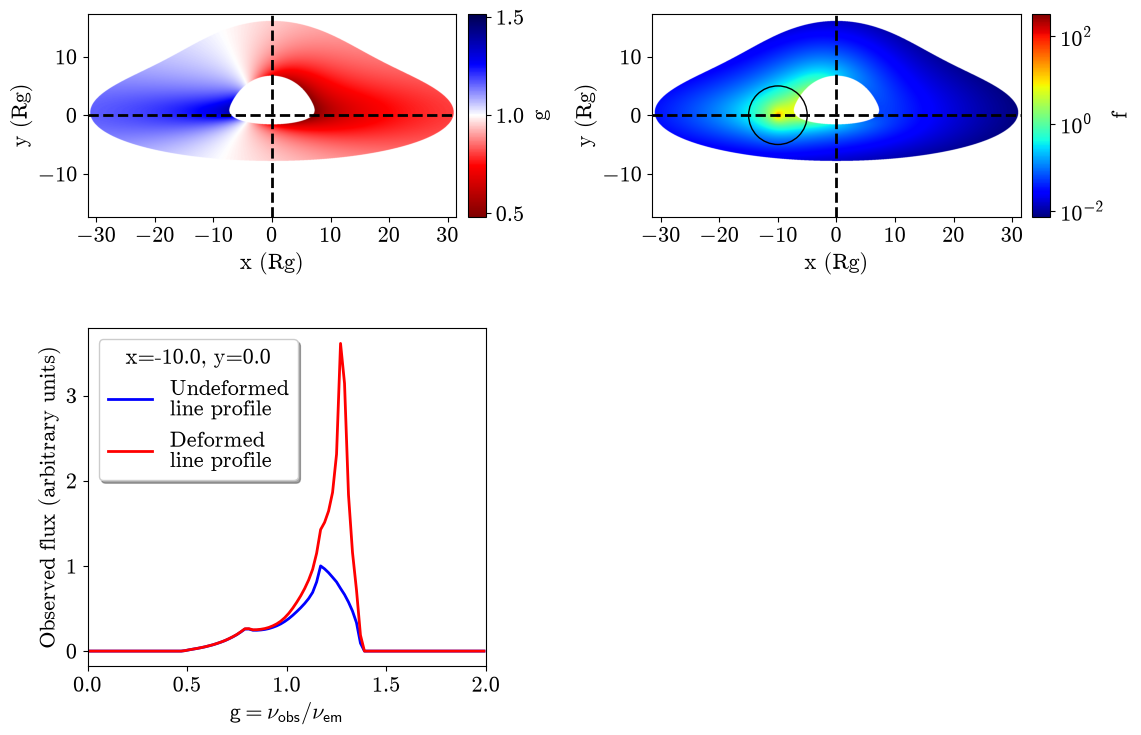

In [4]:
#
# Influence of a point-like microlens on the observed profile of the Fe Kalpha
# spectral line emitted from a relativistic accretion disk whose simulated image
# is stored in the specified input FITS file
#

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2,
    'figure.figsize': [11.69, 8.27]
})

# Distance from the point-like microlens
def u(x, y, xd, yd, re):
    return np.sqrt((x - xd)**2 + (y - yd)**2) / re

# Amplification of the point-like microlens
def amp(x, y, xd, yd, re):
    d = u(x, y, xd, yd, re)
    a = np.full(np.shape(d), np.inf)
    ind = np.where(d != 0)
    a[ind] = (d[ind]**2 + 2.0) / (d[ind] * np.sqrt(d[ind]**2 + 4.0))
    return a

# Input FITS file name (without extension)
filename = 'disk'
# Number of spectral line bins
nbin = 100
# Coordinates and projected Einstein radius (all in R_g) of the point-like microlens
xd = -10.0
yd = 0.0
re = 5.0

# Create the necessary I/O file names
fitsfile = filename + '.fits.gz'
linedat = f'line_x{xd}_y{yd}.dat'
pngfig = f'{filename}_x{xd}_y{yd}.png'

# Read the primary HDU header
h0 = fits.getheader(fitsfile, 0)
a = h0["SPIN"]
theta = h0["ANGLE"]
rin = h0["RINN"]
rout = h0["ROUT"]
q = h0["INDEX"]
print(f"\nDisk parameters:\na = {a}, i = {theta} deg, Rin = {rin} Rg, Rout = {rout} Rg, q = {q}\n")

# Read the data and header from the shift image
g, h1 = fits.getdata(fitsfile, 'SHIFT', header=True)
nx = h1["NAXIS1"]
ny = h1["NAXIS2"]
c1 = h1["CONTENT"]
xt = h1["CTYPE1"]
yt = h1["CTYPE2"]
xu = h1["CUNIT1"]
yu = h1["CUNIT2"]
i0 = h1["CRPIX1"]
j0 = h1["CRPIX2"]
x0 = h1["CRVAL1"]
y0 = h1["CRVAL2"]
dx = h1["CDELT1"]
dy = h1["CDELT2"]

# Extents of x and y axes
xext = (i0 - 1) * dx
yext = (j0 - 1) * dy

# Read the data and header from the flux image
f, h2 = fits.getdata(fitsfile, 'FLUX', header=True)
c2 = h2["CONTENT"]

# Undeformed line profile
valid = ~np.isnan(g) & ~np.isnan(f)
gg = g[valid]
ff = f[valid]

# Compute histogram (binning) directly using np.histogram
gbin = np.linspace(0.0, 2.0, nbin + 1)
fobs, _ = np.histogram(gg, bins=gbin, weights=ff)

# Normalize the maximum flux to 1
fmax = np.max(fobs)
fobs /= fmax

# Find the bin centers
gobs = (gbin[:-1] + gbin[1:]) / 2.0

# Amplified disk flux due to microlensing
x = np.linspace(-xext, xext, nx)
y = np.linspace(-yext, yext, ny)
xi, yi = np.meshgrid(x, y, sparse=False, indexing='xy')
f *= amp(xi, yi, xd, yd, re)

# Microlensed line profile normalized to its undeformed profile
ff_ml = f[valid]
fml, _ = np.histogram(gg, bins=gbin, weights=ff_ml)
fml /= fmax

# Save the spectral line profile
np.savetxt(linedat, np.transpose([gobs, fobs, fml]), fmt='%.7f %.7f %.7f')

# Plot the shift image of the disk
gext = max(1.0 - np.nanmin(g), np.nanmax(g) - 1.0)
ax1 = plt.subplot(221)
im1 = ax1.imshow(g, extent=[-xext, xext, yext, -yext], cmap='seismic_r', vmin=1.0 - gext, vmax=1.0 + gext)
ax1.locator_params(axis='x', nbins=7)
ax1.set_xlabel(f'{xt} ({xu})')
ax1.set_ylabel(f'{yt} ({yu})')
ax1.axhline(0, color='k', linestyle='--')
ax1.axvline(0, color='k', linestyle='--')
ax1.invert_yaxis()
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", "5%", pad="3%")
cbar1 = plt.colorbar(im1, cax=cax1)
cbar1.set_label(c1)

# Plot the flux image of the disk
ax2 = plt.subplot(222)
im2 = ax2.imshow(f, extent=[-xext, xext, yext, -yext], cmap='jet', norm=LogNorm(clip=True))
ax2.locator_params(axis='x', nbins=7)
# Projected Einstein ring of the microlens
ax2.add_patch(Circle((xd, yd), re, color='k', fill=False))
ax2.set_xlabel(f'{xt} ({xu})')
ax2.set_ylabel(f'{yt} ({yu})')
ax2.axhline(0, color='k', linestyle='--')
ax2.axvline(0, color='k', linestyle='--')
ax2.invert_yaxis()
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", "5%", pad="3%")
cbar2 = plt.colorbar(im2, cax=cax2)
cbar2.set_label(c2)

# Plot the undeformed and deformed line profiles
ax3 = plt.subplot(223)
ax3.plot(gobs, fobs, 'b-', label='Undeformed\nline profile')
ax3.plot(gobs, fml, 'r-', label='Deformed\nline profile')
ax3.set_xlim(0.0, 2.0)
ax3.set_xlabel(r'$\mathsf{g=\nu_{obs}/\nu_{em}}$')
ax3.set_ylabel('Observed flux (arbitrary units)')
ax3.legend(loc='upper left', title=f'x={xd}, y={yd}', fancybox=True, shadow=True)

# Adjust subplot spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout()
plt.savefig(pngfig, dpi=300, bbox_inches='tight')
plt.show()



Disk parameters:
a = 0.002, i = 75.0 deg, Rin = 6.0 Rg, Rout = 30.0 Rg, q = -2.5



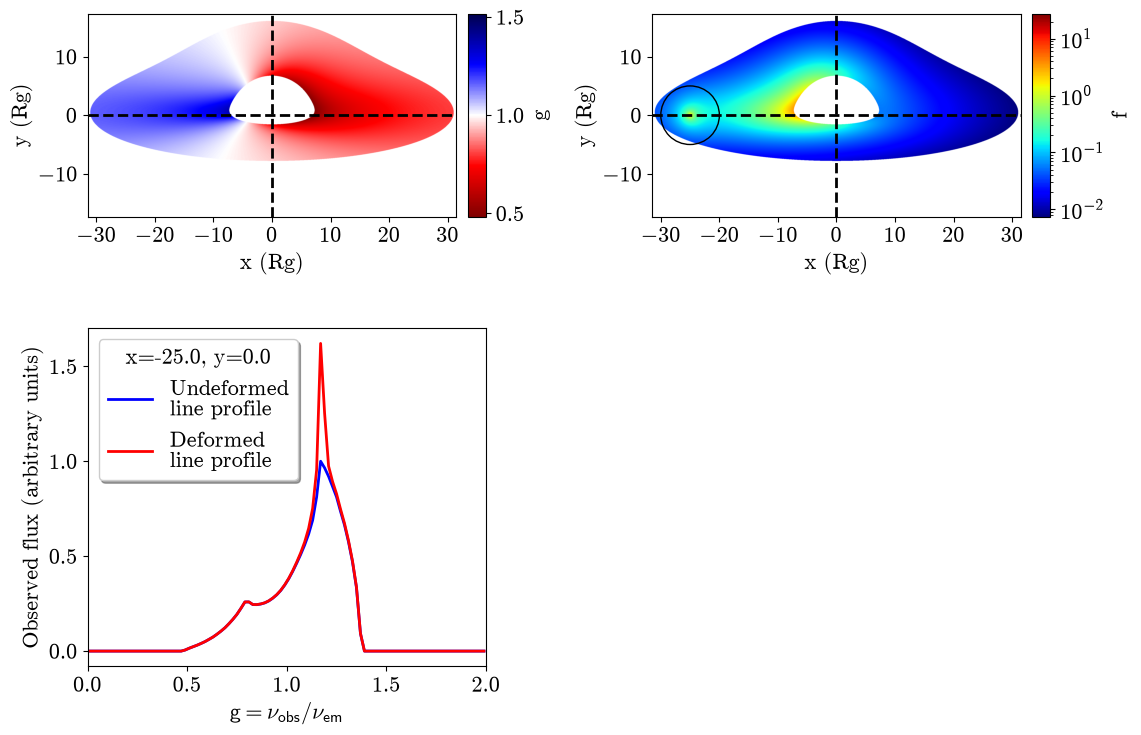

In [5]:
#
# Influence of a point-like microlens on the observed profile of the Fe Kalpha
# spectral line emitted from a relativistic accretion disk whose simulated image
# is stored in the specified input FITS file
#

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2,
    'figure.figsize': [11.69, 8.27]
})

# Distance from the point-like microlens
def u(x, y, xd, yd, re):
    return np.sqrt((x - xd)**2 + (y - yd)**2) / re

# Amplification of the point-like microlens
def amp(x, y, xd, yd, re):
    d = u(x, y, xd, yd, re)
    a = np.full(np.shape(d), np.inf)
    ind = np.where(d != 0)
    a[ind] = (d[ind]**2 + 2.0) / (d[ind] * np.sqrt(d[ind]**2 + 4.0))
    return a

# Input FITS file name (without extension)
filename = 'disk'
# Number of spectral line bins
nbin = 100
# Coordinates and projected Einstein radius (all in R_g) of the point-like microlens
xd = -25.0
yd = 0.0
re = 5.0

# Create the necessary I/O file names
fitsfile = filename + '.fits.gz'
linedat = f'line_x{xd}_y{yd}.dat'
pngfig = f'{filename}_x{xd}_y{yd}.png'

# Read the primary HDU header
h0 = fits.getheader(fitsfile, 0)
a = h0["SPIN"]
theta = h0["ANGLE"]
rin = h0["RINN"]
rout = h0["ROUT"]
q = h0["INDEX"]
print(f"\nDisk parameters:\na = {a}, i = {theta} deg, Rin = {rin} Rg, Rout = {rout} Rg, q = {q}\n")

# Read the data and header from the shift image
g, h1 = fits.getdata(fitsfile, 'SHIFT', header=True)
nx = h1["NAXIS1"]
ny = h1["NAXIS2"]
c1 = h1["CONTENT"]
xt = h1["CTYPE1"]
yt = h1["CTYPE2"]
xu = h1["CUNIT1"]
yu = h1["CUNIT2"]
i0 = h1["CRPIX1"]
j0 = h1["CRPIX2"]
x0 = h1["CRVAL1"]
y0 = h1["CRVAL2"]
dx = h1["CDELT1"]
dy = h1["CDELT2"]

# Extents of x and y axes
xext = (i0 - 1) * dx
yext = (j0 - 1) * dy

# Read the data and header from the flux image
f, h2 = fits.getdata(fitsfile, 'FLUX', header=True)
c2 = h2["CONTENT"]

# Undeformed line profile
valid = ~np.isnan(g) & ~np.isnan(f)
gg = g[valid]
ff = f[valid]

# Compute histogram (binning) directly using np.histogram
gbin = np.linspace(0.0, 2.0, nbin + 1)
fobs, _ = np.histogram(gg, bins=gbin, weights=ff)

# Normalize the maximum flux to 1
fmax = np.max(fobs)
fobs /= fmax

# Find the bin centers
gobs = (gbin[:-1] + gbin[1:]) / 2.0

# Amplified disk flux due to microlensing
x = np.linspace(-xext, xext, nx)
y = np.linspace(-yext, yext, ny)
xi, yi = np.meshgrid(x, y, sparse=False, indexing='xy')
f *= amp(xi, yi, xd, yd, re)

# Microlensed line profile normalized to its undeformed profile
ff_ml = f[valid]
fml, _ = np.histogram(gg, bins=gbin, weights=ff_ml)
fml /= fmax

# Save the spectral line profile
np.savetxt(linedat, np.transpose([gobs, fobs, fml]), fmt='%.7f %.7f %.7f')

# Plot the shift image of the disk
gext = max(1.0 - np.nanmin(g), np.nanmax(g) - 1.0)
ax1 = plt.subplot(221)
im1 = ax1.imshow(g, extent=[-xext, xext, yext, -yext], cmap='seismic_r', vmin=1.0 - gext, vmax=1.0 + gext)
ax1.locator_params(axis='x', nbins=7)
ax1.set_xlabel(f'{xt} ({xu})')
ax1.set_ylabel(f'{yt} ({yu})')
ax1.axhline(0, color='k', linestyle='--')
ax1.axvline(0, color='k', linestyle='--')
ax1.invert_yaxis()
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", "5%", pad="3%")
cbar1 = plt.colorbar(im1, cax=cax1)
cbar1.set_label(c1)

# Plot the flux image of the disk
ax2 = plt.subplot(222)
im2 = ax2.imshow(f, extent=[-xext, xext, yext, -yext], cmap='jet', norm=LogNorm(clip=True))
ax2.locator_params(axis='x', nbins=7)
# Projected Einstein ring of the microlens
ax2.add_patch(Circle((xd, yd), re, color='k', fill=False))
ax2.set_xlabel(f'{xt} ({xu})')
ax2.set_ylabel(f'{yt} ({yu})')
ax2.axhline(0, color='k', linestyle='--')
ax2.axvline(0, color='k', linestyle='--')
ax2.invert_yaxis()
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", "5%", pad="3%")
cbar2 = plt.colorbar(im2, cax=cax2)
cbar2.set_label(c2)

# Plot the undeformed and deformed line profiles
ax3 = plt.subplot(223)
ax3.plot(gobs, fobs, 'b-', label='Undeformed\nline profile')
ax3.plot(gobs, fml, 'r-', label='Deformed\nline profile')
ax3.set_xlim(0.0, 2.0)
ax3.set_xlabel(r'$\mathsf{g=\nu_{obs}/\nu_{em}}$')
ax3.set_ylabel('Observed flux (arbitrary units)')
ax3.legend(loc='upper left', title=f'x={xd}, y={yd}', fancybox=True, shadow=True)

# Adjust subplot spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.tight_layout()
plt.savefig(pngfig, dpi=300, bbox_inches='tight')
plt.show()


# Exercise 2

(2000, 2000)


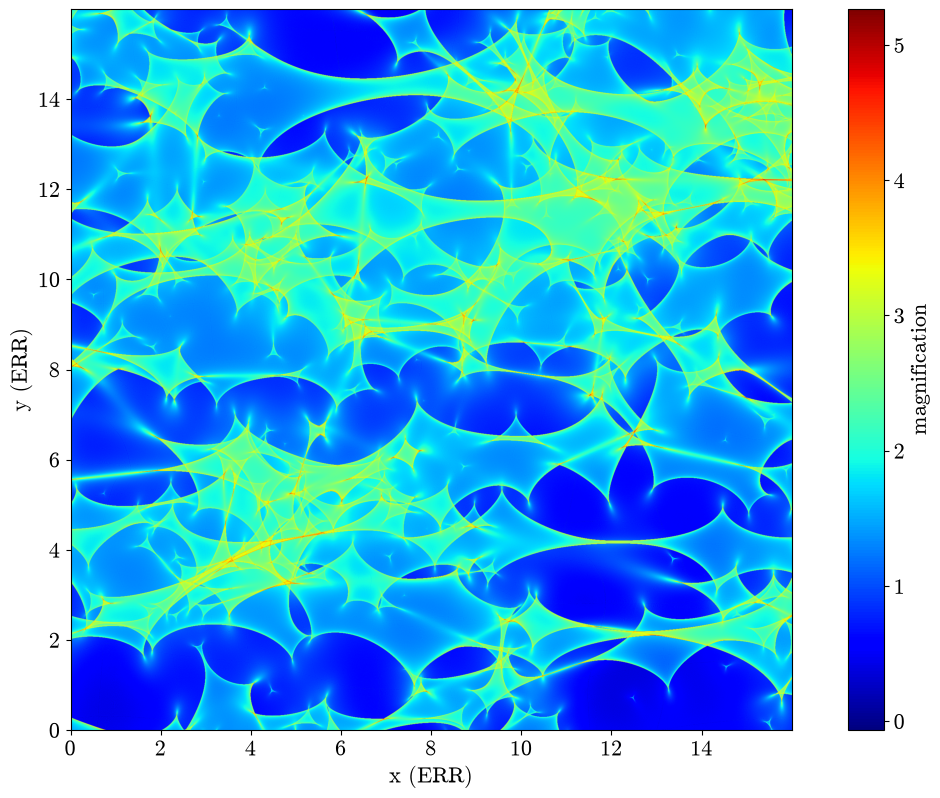

In [6]:
# Read and display the specified FITS image
#

import matplotlib.pyplot as plt
from astropy.io import fits

# Input FITS file name (without extension)
filename = 'mlmap'

# Create the necessary I/O file names
input_fits = filename + '.fits.gz'
output_fig = filename + '.png'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
print(data.shape)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
ct = header["CONTENT"]
xt = header["CTYPE1"]
yt = header["CTYPE2"]
xu = header["CUNIT1"]
yu = header["CUNIT2"]
i0 = header["CRPIX1"]
j0 = header["CRPIX2"]
x0 = header["CRVAL1"]
y0 = header["CRVAL2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Extents of x and y axes
if i0 == (nx + 1) / 2:
    xmin = -(i0 - 1) * dx
    xmax = (i0 - 1) * dx
else:
    xmin = x0
    xmax = x0 + (nx - 1) * dx

if j0 == (ny + 1) / 2:
    ymin = -(j0 - 1) * dy
    ymax = (j0 - 1) * dy
else:
    ymin = y0
    ymax = y0 + (ny - 1) * dy

# Plot the input image versus axes in real units
plt.imshow(data, extent=[xmin, xmax, ymax, ymin], cmap='jet')
plt.xlabel(f'{xt} ({xu})')
plt.ylabel(f'{yt} ({yu})')
plt.gca().invert_yaxis()
cbar = plt.colorbar(format='%1.2g')
cbar.set_label(ct)
plt.tight_layout()
plt.savefig(output_fig, dpi=300, bbox_inches='tight')
plt.show()


In [7]:
#
# Calculate a circular source with 2D Gaussian brightness distribution,
# read the input microlensing magnification map and convolve it with
# the source. Save the output into the specified FITS files.
#

import numpy as np
from scipy.signal import fftconvolve
from astropy.io import fits

# Save either extended source (ft == 1) or microlensing map (ft != 1)
# into the specified FITS file
def save_fits(ft, fname, z, i0, dx, j0, dy):
    h = fits.Header()
    if ft == 1:
        h.set('CONTENT', 'brightness', 'file contains extended circular source')
    else:
        h.set('CONTENT', 'magnification', 'file contains microlensing magnification map')
    h.set('CTYPE1', 'x', 'type of data axis 1')
    h.set('CUNIT1', 'ERR', 'units of data axis 1')
    h.set('CRPIX1', i0, 'reference pixel of data axis 1')
    h.set('CRVAL1', 0.0, 'coordinate of reference pixel of data axis 1')
    h.set('CDELT1', dx, 'increment (pixel size) along data axis 1')
    h.set('CTYPE2', 'y', 'type of data axis 2')
    h.set('CUNIT2', 'ERR', 'units of data axis 2')
    h.set('CRPIX2', j0, 'reference pixel of data axis 2')
    h.set('CRVAL2', 0.0, 'coordinate of reference pixel of data axis 2')
    h.set('CDELT2', dy, 'increment (pixel size) along data axis 2')
    h.set('ORIGIN', 'P. Jovanovic (AOB)', 'origin of FITS file')
    hdu = fits.PrimaryHDU(data=z, header=h)
    hdu.writeto(fname, overwrite=True)

# Input file name of the microlensing map (without extension)
inpfil = 'mlmap'
# Output file name of the extended source (without extension)
outfil = 'source1'
# Radius of the extended circular source and standard deviation
# of its Gaussian brightness distribution (both in ERR)
rs = 0.8
ss = 0.4

# Create the necessary I/O FITS file names
input_fits = inpfil + '.fits.gz'
output_fits1 = outfil + '.fits.gz'
output_fits2 = f'{inpfil}_{outfil}.fits.gz'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Create the extended circular source with 2D Gaussian distribution of brightness
m = int(rs / dx + 0.5)
n = int(rs / dy + 0.5)
x = np.arange(-m, m + 1, 1, dtype=float) * dx
y = np.arange(-n, n + 1, 1, dtype=float) * dy
xx, yy = np.meshgrid(x, y)
z = np.exp(-(xx**2 + yy**2) / (2.0 * ss**2))
z[xx**2 + yy**2 > rs**2] = np.nan

# Write the extended source image into the first output FITS file
save_fits(1, output_fits1, z, m + 1, dx, n + 1, dy)
fits.info(output_fits1)

# Normalize the source so that its total brightness equals 1,
# convolve the microlensing map with the normalized source,
# and keep only the central part matching the input map dimensions
z[np.isnan(z)] = 0.0
z /= np.sum(z)
c = fftconvolve(data, z, mode='same')

# Write the microlensing magnification map for the extended source into
# the second output FITS file
save_fits(2, output_fits2, c, 1, dx, 1, dy)
fits.info(output_fits2)

Filename: source1.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      17   (201, 201)   float64   
Filename: mlmap_source1.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      17   (2000, 2000)   float64   


(201, 201)


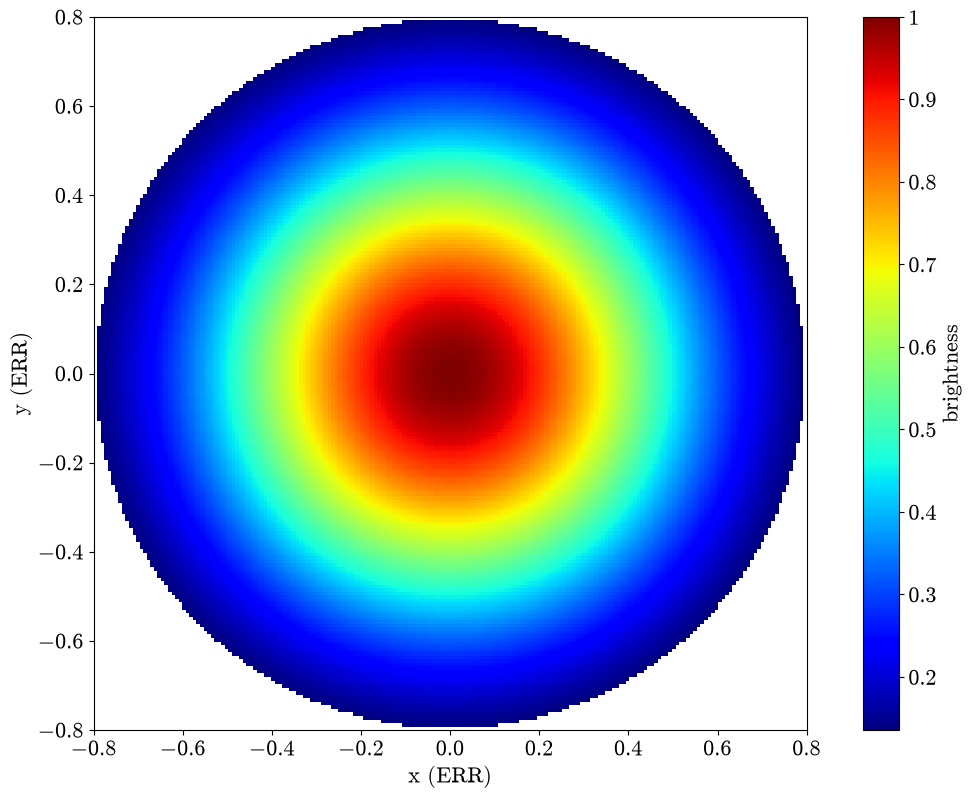

In [10]:
#
# Read and display the specified FITS image
#

import matplotlib.pyplot as plt
from astropy.io import fits

# Input FITS file name (without extension)
filename = 'source1'

# Create the necessary I/O file names
input_fits = filename + '.fits.gz'
output_fig = filename + '.png'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
print(data.shape)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
ct = header["CONTENT"]
xt = header["CTYPE1"]
yt = header["CTYPE2"]
xu = header["CUNIT1"]
yu = header["CUNIT2"]
i0 = header["CRPIX1"]
j0 = header["CRPIX2"]
x0 = header["CRVAL1"]
y0 = header["CRVAL2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Extents of x and y axes
if i0 == (nx + 1) / 2:
    xmin = -(i0 - 1) * dx
    xmax = (i0 - 1) * dx
else:
    xmin = x0
    xmax = x0 + (nx - 1) * dx

if j0 == (ny + 1) / 2:
    ymin = -(j0 - 1) * dy
    ymax = (j0 - 1) * dy
else:
    ymin = y0
    ymax = y0 + (ny - 1) * dy

# Plot the input image versus axes in real units
plt.imshow(data, extent=[xmin, xmax, ymax, ymin], cmap='jet')
plt.xlabel(f'{xt} ({xu})')
plt.ylabel(f'{yt} ({yu})')
plt.gca().invert_yaxis()
cbar = plt.colorbar(format='%1.2g')
cbar.set_label(ct)
plt.tight_layout()
plt.savefig(output_fig, dpi=300, bbox_inches='tight')
plt.show()


(2000, 2000)


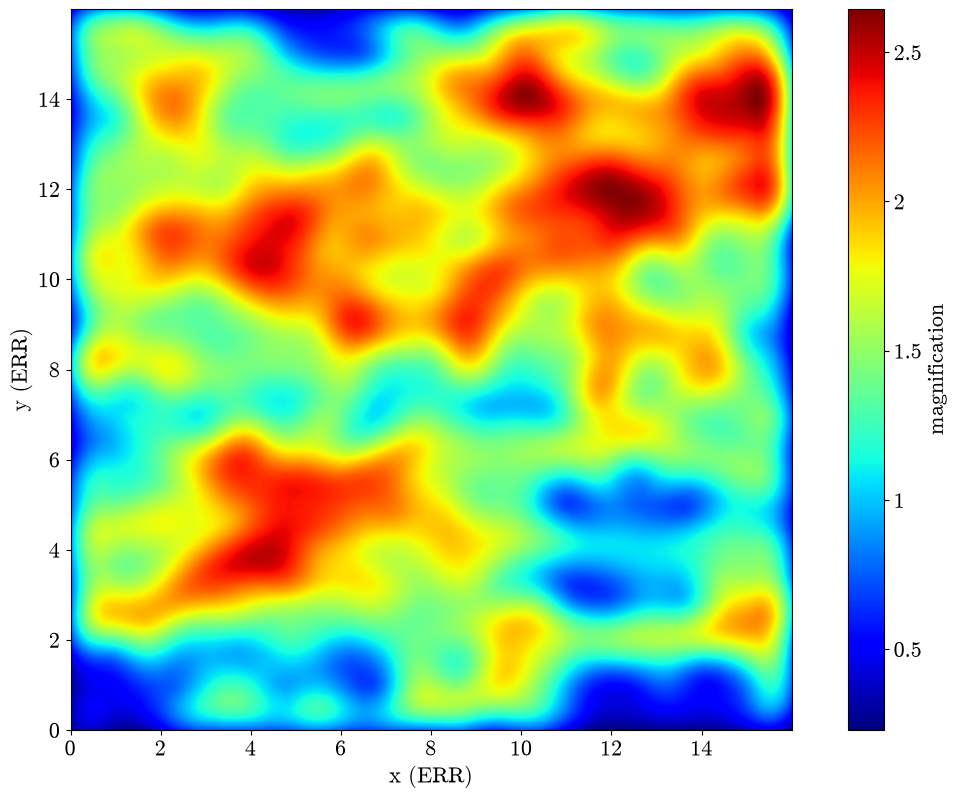

In [11]:
#
# Read and display the specified FITS image
#

import matplotlib.pyplot as plt
from astropy.io import fits

# Input FITS file name (without extension)
filename = 'mlmap_source1'

# Create the necessary I/O file names
input_fits = filename + '.fits.gz'
output_fig = filename + '.png'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
print(data.shape)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
ct = header["CONTENT"]
xt = header["CTYPE1"]
yt = header["CTYPE2"]
xu = header["CUNIT1"]
yu = header["CUNIT2"]
i0 = header["CRPIX1"]
j0 = header["CRPIX2"]
x0 = header["CRVAL1"]
y0 = header["CRVAL2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Extents of x and y axes
if i0 == (nx + 1) / 2:
    xmin = -(i0 - 1) * dx
    xmax = (i0 - 1) * dx
else:
    xmin = x0
    xmax = x0 + (nx - 1) * dx

if j0 == (ny + 1) / 2:
    ymin = -(j0 - 1) * dy
    ymax = (j0 - 1) * dy
else:
    ymin = y0
    ymax = y0 + (ny - 1) * dy

# Plot the input image versus axes in real units
plt.imshow(data, extent=[xmin, xmax, ymax, ymin], cmap='jet')
plt.xlabel(f'{xt} ({xu})')
plt.ylabel(f'{yt} ({yu})')
plt.gca().invert_yaxis()
cbar = plt.colorbar(format='%1.2g')
cbar.set_label(ct)
plt.tight_layout()
plt.savefig(output_fig, dpi=300, bbox_inches='tight')
plt.show()


In [16]:
# foR SOURCE 2
# Calculate a circular source with 2D Gaussian brightness distribution,
# read the input microlensing magnification map and convolve it with
# the source. Save the output into the specified FITS files.
#

import numpy as np
from scipy.signal import fftconvolve
from astropy.io import fits

# Save either extended source (ft == 1) or microlensing map (ft != 1)
# into the specified FITS file
def save_fits(ft, fname, z, i0, dx, j0, dy):
    h = fits.Header()
    if ft == 1:
        h.set('CONTENT', 'brightness', 'file contains extended circular source')
    else:
        h.set('CONTENT', 'magnification', 'file contains microlensing magnification map')
    h.set('CTYPE1', 'x', 'type of data axis 1')
    h.set('CUNIT1', 'ERR', 'units of data axis 1')
    h.set('CRPIX1', i0, 'reference pixel of data axis 1')
    h.set('CRVAL1', 0.0, 'coordinate of reference pixel of data axis 1')
    h.set('CDELT1', dx, 'increment (pixel size) along data axis 1')
    h.set('CTYPE2', 'y', 'type of data axis 2')
    h.set('CUNIT2', 'ERR', 'units of data axis 2')
    h.set('CRPIX2', j0, 'reference pixel of data axis 2')
    h.set('CRVAL2', 0.0, 'coordinate of reference pixel of data axis 2')
    h.set('CDELT2', dy, 'increment (pixel size) along data axis 2')
    h.set('ORIGIN', 'P. Jovanovic (AOB)', 'origin of FITS file')
    hdu = fits.PrimaryHDU(data=z, header=h)
    hdu.writeto(fname, overwrite=True)

# Input file name of the microlensing map (without extension)
inpfil = 'mlmap'
# Output file name of the extended source (without extension)
outfil = 'source2'
# Radius of the extended circular source and standard deviation
# of its Gaussian brightness distribution (both in ERR)
rs = 0.8
ss = 0.1#
# Microlensing light curves for a point-like and two extended
# circular sources, moving with the given effective velocity
#

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True
})

# Coordinates of the start and end points (in ERR)
pos1 = [1.0, 1.0]
pos2 = [15.0, 15.0]
# Redshift of the lens
zd = 0.5
# Effective velocity of the source (in ERR/yr)
vs = 5.0

# Read the data and header from the 1st input FITS file
z1, header = fits.getdata('mlmap.fits.gz', header=True)
dx = header["CDELT1"]
dy = header["CDELT2"]
# Read the data from the 2nd input FITS file
z2 = fits.getdata('mlmap_source1.fits.gz')
# Read the data from the 3rd input FITS file
z3 = fits.getdata('mlmap_source2.fits.gz')

# Map the start and end coordinates to their pixel indices
i1 = int(pos1[0] / dx + 0.5)
i2 = int(pos2[0] / dx + 1.5)
j1 = int(pos1[1] / dy + 0.5)
j2 = int(pos2[1] / dy + 1.5)

# Diagonal distances from the start point
x = np.arange(i1, i2, 1, dtype=float) * dx
y = np.arange(j1, j2, 1, dtype=float) * dy
d = np.sqrt((x - x[0])**2 + (y - y[0])**2)

# The corresponding time scale
t = (1.0 + zd) * d / vs

# The corresponding magnifications in all 3 maps (FITS arrays are indexed as [y, x])
m1 = np.diagonal(z1[j1:j2, i1:i2])
m2 = np.diagonal(z2[j1:j2, i1:i2])
m3 = np.diagonal(z3[j1:j2, i1:i2])

# Save and plot the light curves
np.savetxt('light_curves.dat', np.transpose([t, m1, m2, m3]), fmt='%.7f %.7f %.7f %.7f')
plt.plot(t, m1, 'r-', label='Point-like source')
plt.plot(t, m2, 'g-', label=r'Circular source ($\sigma=0.4$)')
plt.plot(t, m3, 'b-', label=r'Circular source ($\sigma=0.1$)')
plt.xlim(0.0, np.max(t))
plt.ylim(0.5, 5.0)
plt.xlabel('Time (in years)')
plt.ylabel('Magnification')
plt.legend(loc='upper center', fancybox=True, shadow=True)
plt.tight_layout()
plt.savefig('light_curves.png', dpi=300, bbox_inches='tight')
plt.show()


# Create the necessary I/O FITS file names
input_fits = inpfil + '.fits.gz'
output_fits1 = outfil + '.fits.gz'
output_fits2 = f'{inpfil}_{outfil}.fits.gz'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Create the extended circular source with 2D Gaussian distribution of brightness
m = int(rs / dx + 0.5)
n = int(rs / dy + 0.5)
x = np.arange(-m, m + 1, 1, dtype=float) * dx
y = np.arange(-n, n + 1, 1, dtype=float) * dy
xx, yy = np.meshgrid(x, y)
z = np.exp(-(xx**2 + yy**2) / (2.0 * ss**2))
z[xx**2 + yy**2 > rs**2] = np.nan

# Write the extended source image into the first output FITS file
save_fits(1, output_fits1, z, m + 1, dx, n + 1, dy)
fits.info(output_fits1)

# Normalize the source so that its total brightness equals 1,
# convolve the microlensing map with the normalized source,
# and keep only the central part matching the input map dimensions
z[np.isnan(z)] = 0.0
z /= np.sum(z)
c = fftconvolve(data, z, mode='same')

# Write the microlensing magnification map for the extended source into
# the second output FITS file
save_fits(2, output_fits2, c, 1, dx, 1, dy)
fits.info(output_fits2)

Filename: source2.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      17   (201, 201)   float64   
Filename: mlmap_source2.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      17   (2000, 2000)   float64   


(201, 201)


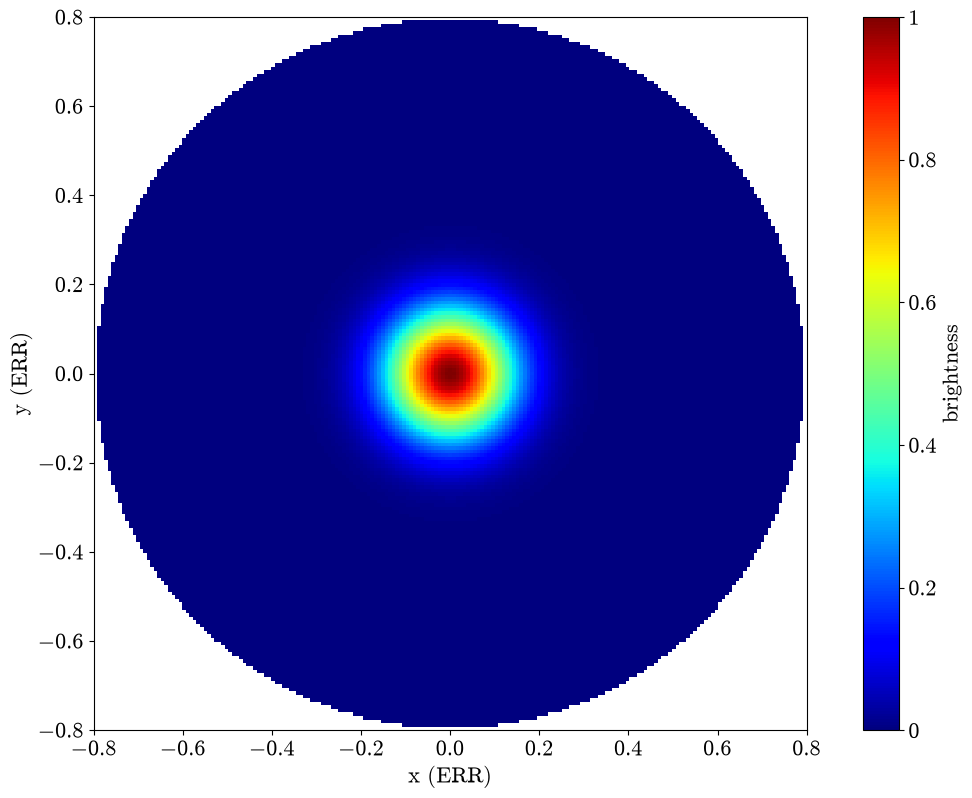

In [17]:
#
# Read and display the specified FITS image
#

import matplotlib.pyplot as plt
from astropy.io import fits

# Input FITS file name (without extension)
filename = 'source2'

# Create the necessary I/O file names
input_fits = filename + '.fits.gz'
output_fig = filename + '.png'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
print(data.shape)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
ct = header["CONTENT"]
xt = header["CTYPE1"]
yt = header["CTYPE2"]
xu = header["CUNIT1"]
yu = header["CUNIT2"]
i0 = header["CRPIX1"]
j0 = header["CRPIX2"]
x0 = header["CRVAL1"]
y0 = header["CRVAL2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Extents of x and y axes
if i0 == (nx + 1) / 2:
    xmin = -(i0 - 1) * dx
    xmax = (i0 - 1) * dx
else:
    xmin = x0
    xmax = x0 + (nx - 1) * dx

if j0 == (ny + 1) / 2:
    ymin = -(j0 - 1) * dy
    ymax = (j0 - 1) * dy
else:
    ymin = y0
    ymax = y0 + (ny - 1) * dy

# Plot the input image versus axes in real units
plt.imshow(data, extent=[xmin, xmax, ymax, ymin], cmap='jet')
plt.xlabel(f'{xt} ({xu})')
plt.ylabel(f'{yt} ({yu})')
plt.gca().invert_yaxis()
cbar = plt.colorbar(format='%1.2g')
cbar.set_label(ct)
plt.tight_layout()
plt.savefig(output_fig, dpi=300, bbox_inches='tight')
plt.show()


(2000, 2000)


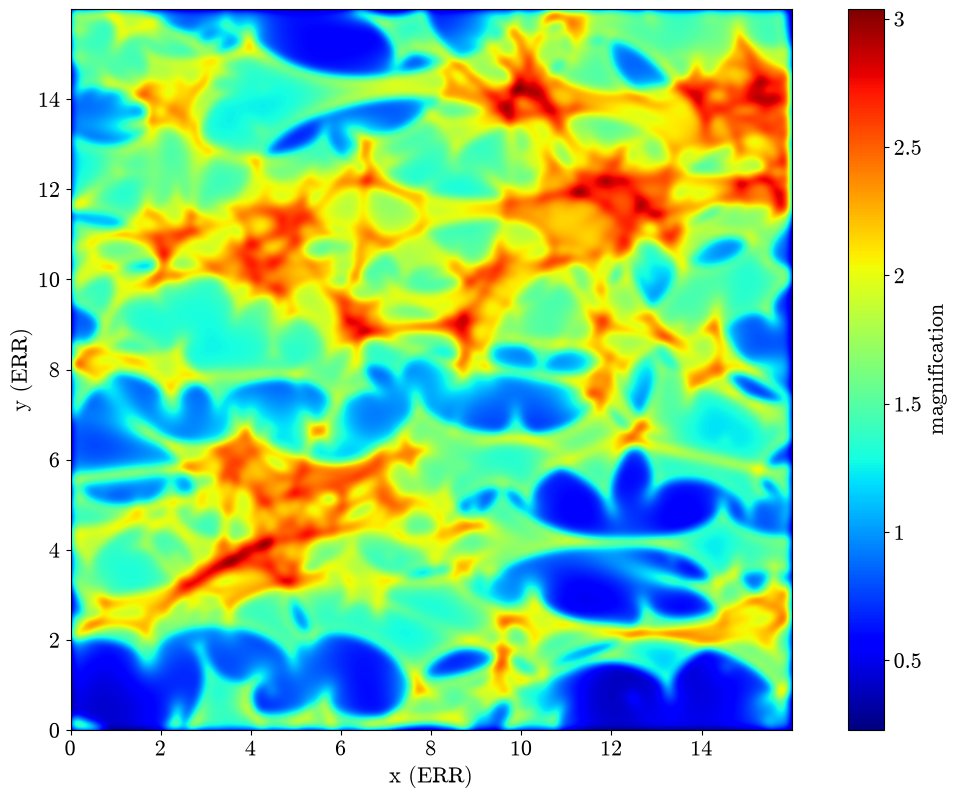

In [18]:
#
# Read and display the specified FITS image
#

import matplotlib.pyplot as plt
from astropy.io import fits

# Input FITS file name (without extension)
filename = 'mlmap_source1'

# Create the necessary I/O file names
input_fits = filename + '.fits.gz'
output_fig = filename + '.png'

# Read the data and header from input FITS file
data, header = fits.getdata(input_fits, header=True)
print(data.shape)
nx = header["NAXIS1"]
ny = header["NAXIS2"]
ct = header["CONTENT"]
xt = header["CTYPE1"]
yt = header["CTYPE2"]
xu = header["CUNIT1"]
yu = header["CUNIT2"]
i0 = header["CRPIX1"]
j0 = header["CRPIX2"]
x0 = header["CRVAL1"]
y0 = header["CRVAL2"]
dx = header["CDELT1"]
dy = header["CDELT2"]

# Extents of x and y axes
if i0 == (nx + 1) / 2:
    xmin = -(i0 - 1) * dx
    xmax = (i0 - 1) * dx
else:
    xmin = x0
    xmax = x0 + (nx - 1) * dx

if j0 == (ny + 1) / 2:
    ymin = -(j0 - 1) * dy
    ymax = (j0 - 1) * dy
else:
    ymin = y0
    ymax = y0 + (ny - 1) * dy

# Plot the input image versus axes in real units
plt.imshow(data, extent=[xmin, xmax, ymax, ymin], cmap='jet')
plt.xlabel(f'{xt} ({xu})')
plt.ylabel(f'{yt} ({yu})')
plt.gca().invert_yaxis()
cbar = plt.colorbar(format='%1.2g')
cbar.set_label(ct)
plt.tight_layout()
plt.savefig(output_fig, dpi=300, bbox_inches='tight')
plt.show()


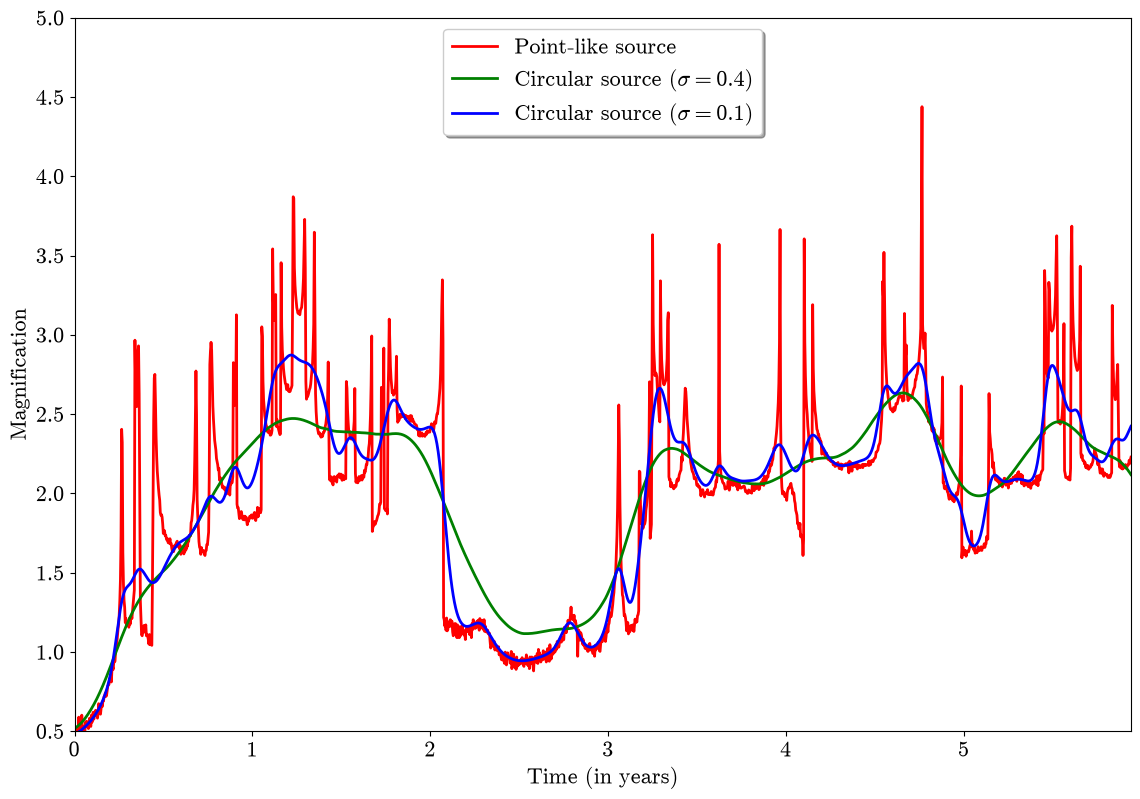

In [19]:
#
# Microlensing light curves for a point-like and two extended
# circular sources, moving with the given effective velocity
#

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True
})

# Coordinates of the start and end points (in ERR)
pos1 = [1.0, 1.0]
pos2 = [15.0, 15.0]
# Redshift of the lens
zd = 0.5
# Effective velocity of the source (in ERR/yr)
vs = 5.0

# Read the data and header from the 1st input FITS file
z1, header = fits.getdata('mlmap.fits.gz', header=True)
dx = header["CDELT1"]
dy = header["CDELT2"]
# Read the data from the 2nd input FITS file
z2 = fits.getdata('mlmap_source1.fits.gz')
# Read the data from the 3rd input FITS file
z3 = fits.getdata('mlmap_source2.fits.gz')

# Map the start and end coordinates to their pixel indices
i1 = int(pos1[0] / dx + 0.5)
i2 = int(pos2[0] / dx + 1.5)
j1 = int(pos1[1] / dy + 0.5)
j2 = int(pos2[1] / dy + 1.5)

# Diagonal distances from the start point
x = np.arange(i1, i2, 1, dtype=float) * dx
y = np.arange(j1, j2, 1, dtype=float) * dy
d = np.sqrt((x - x[0])**2 + (y - y[0])**2)

# The corresponding time scale
t = (1.0 + zd) * d / vs

# The corresponding magnifications in all 3 maps (FITS arrays are indexed as [y, x])
m1 = np.diagonal(z1[j1:j2, i1:i2])
m2 = np.diagonal(z2[j1:j2, i1:i2])
m3 = np.diagonal(z3[j1:j2, i1:i2])

# Save and plot the light curves
np.savetxt('light_curves.dat', np.transpose([t, m1, m2, m3]), fmt='%.7f %.7f %.7f %.7f')
plt.plot(t, m1, 'r-', label='Point-like source')
plt.plot(t, m2, 'g-', label=r'Circular source ($\sigma=0.4$)')
plt.plot(t, m3, 'b-', label=r'Circular source ($\sigma=0.1$)')
plt.xlim(0.0, np.max(t))
plt.ylim(0.5, 5.0)
plt.xlabel('Time (in years)')
plt.ylabel('Magnification')
plt.legend(loc='upper center', fancybox=True, shadow=True)
plt.tight_layout()
plt.savefig('light_curves.png', dpi=300, bbox_inches='tight')
plt.show()


# Exercise 3

In [20]:
import numpy as np
from scipy.integrate import quad

# Integrand for comoving distance (flat Lambda-CDM cosmology)
def ez(z, om):
    return 1.0 / np.sqrt(om * (1.0 + z)**3.0 + 1.0 - om)

# Comoving distance (eq. 15 in Hogg 2000)
def dc(z, om, h0):
    return 299792.458 * quad(ez, 0.0, z, args=(om))[0] / h0

# Angular diameter distance (eq. 18 in Hogg 2000)
def da(z, om, h0):
    return dc(z, om, h0) / (1.0 + z)

zl = float(input('Enter the lens redshift: '))
zs = float(input('Enter the source redshift: '))
rs = float(input('Enter the source radius (in km): '))
vs = float(input('Enter the effective source velocity (in km/s): '))
h0 = float(input('Enter the Hubble constant (in km/s/Mpc): '))
om = float(input('Enter the Omega_matter: '))

dl = da(zl, om, h0)
ds = da(zs, om, h0)
tc = (1.0 + zl) * dl * rs / (vs * ds)
# Convert tc from seconds to days
tc = tc / 86400.0

print(f'\nAngular diameter distance of the lens: {dl:.1f} Mpc')
print(f'Angular diameter distance of the source: {ds:.1f} Mpc')
print(f'Microlensing crossing time: {tc:.1f} days')


Enter the lens redshift:  0.5
Enter the source redshift:  2
Enter the source radius (in km):  1.5e+10
Enter the effective source velocity (in km/s):  600
Enter the Hubble constant (in km/s/Mpc):  75
Enter the Omega_matter:  0.3



Angular diameter distance of the lens: 1175.1 Mpc
Angular diameter distance of the source: 1611.5 Mpc
Microlensing crossing time: 316.5 days


In [ ]:
import numpy as np
from scipy.integrate import quad

# Integrand for comoving distance (flat Lambda-CDM cosmology)
def ez(z, om):
    return 1.0 / np.sqrt(om * (1.0 + z)**3.0 + 1.0 - om)

# Comoving distance (eq. 15 in Hogg 2000)
def dc(z, om, h0):
    return 299792.458 * quad(ez, 0.0, z, args=(om))[0] / h0

# Angular diameter distance (eq. 18 in Hogg 2000)
def da(z, om, h0):
    return dc(z, om, h0) / (1.0 + z)

zl = float(input('Enter the lens redshift: '))
zs = float(input('Enter the source redshift: '))
rs = float(input('Enter the source radius (in km): '))
vs = float(input('Enter the effective source velocity (in km/s): '))
h0 = float(input('Enter the Hubble constant (in km/s/Mpc): '))
om = float(input('Enter the Omega_matter: '))

dl = da(zl, om, h0)
ds = da(zs, om, h0)
tc = (1.0 + zl) * dl * rs / (vs * ds)
# Convert tc from seconds to days
tc = tc / 86400.0

print(f'\nAngular diameter distance of the lens: {dl:.1f} Mpc')
print(f'Angular diameter distance of the source: {ds:.1f} Mpc')
print(f'Microlensing crossing time: {tc:.1f} days')
